# Forest Fire Prediction - Model Training & Evaluation

### 1. Import Libraries

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create directories for models and figures
os.makedirs('models', exist_ok=True)
os.makedirs('figures', exist_ok=True)
print("Libraries imported and directories initialized.")

Libraries imported and directories initialized.


### 2. Load the Cleaned Dataset

In [2]:
# Load cleaned dataset
df = pd.read_csv('Dataset/cleaned_forest_fires.csv')

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (513, 14)


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area,area_log1p
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0,0.0


### 3. Recreate 80/20 Stratified Train/Test Split

In [3]:
# Feature group definitions
categorical = ['month', 'day']
weather = ['FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH', 'wind', 'rain']
spatial = ['X', 'Y']

features_non_spatial = categorical + weather
features_spatial = spatial + categorical + weather

# Stratification label based on zero-area records
strat_label = (df['area'] == 0)

train_idx, test_idx = train_test_split(
    df.index, test_size=0.20, random_state=42, stratify=strat_label
)

# Training and test feature sets
X_train_ns = df.loc[train_idx, features_non_spatial]
X_test_ns = df.loc[test_idx, features_non_spatial]

X_train_s = df.loc[train_idx, features_spatial]
X_test_s = df.loc[test_idx, features_spatial]

# Target variables: log1p for training, original area for evaluation in hectares
y_train = df.loc[train_idx, 'area_log1p']
y_test = df.loc[test_idx, 'area_log1p']

y_train_area = df.loc[train_idx, 'area']
y_test_area = df.loc[test_idx, 'area']

print(f"Training samples: {len(X_train_ns)} | Testing samples: {len(X_test_ns)}")
print(f"Non-spatial inputs: {len(features_non_spatial)} | Spatial inputs: {len(features_spatial)}")

Training samples: 410 | Testing samples: 103
Non-spatial inputs: 10 | Spatial inputs: 12


### 4. Preprocessing Pipeline Builder

In [4]:
months = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
days = ['mon', 'tue', 'wed', 'thu', 'fri', 'sat', 'sun']

def build_preprocessor(include_spatial=False):
    """Build ColumnTransformer for categorical and numerical features."""
    ohe = OneHotEncoder(categories=[months, days], drop='first', sparse_output=False, handle_unknown='ignore')
    scaler = StandardScaler()
    num_cols = (spatial + weather) if include_spatial else weather
    return ColumnTransformer([
        ('cat', ohe, categorical),
        ('num', scaler, num_cols)
    ])

# 5-fold Stratified CV splits
strat_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_splits = list(strat_cv.split(X_train_ns, (y_train_area == 0)))

scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2'
}

print("Preprocessor builder and 5-fold CV splits configured.")

Preprocessor builder and 5-fold CV splits configured.


### 5. Naive Baseline Model

In [5]:
# Baseline dummy model predicting mean
dummy_model = DummyRegressor(strategy='mean')
dummy_cv = cross_validate(
    dummy_model,
    np.zeros((len(y_train), 1)),
    y_train,
    cv=cv_splits,
    scoring=scoring
)

baseline_mae = -dummy_cv['test_mae'].mean()
baseline_rmse = -dummy_cv['test_rmse'].mean()
baseline_r2 = dummy_cv['test_r2'].mean()

print(f"Baseline -> MAE: {baseline_mae:.4f} | RMSE: {baseline_rmse:.4f} | R2: {baseline_r2:.4f}")

Baseline -> MAE: 1.1833 | RMSE: 1.4117 | R2: -0.0043


### 6. Linear Regression & Diagnostic Check

In [6]:
# Linear Regression pipeline
lr_pipeline = Pipeline([
    ('preprocessor', build_preprocessor(include_spatial=False)),
    ('model', LinearRegression())
])

lr_cv = cross_validate(
    lr_pipeline,
    X_train_ns,
    y_train,
    cv=cv_splits,
    scoring=scoring
)

lr_mae = -lr_cv['test_mae'].mean()
lr_rmse = -lr_cv['test_rmse'].mean()
lr_r2 = lr_cv['test_r2'].mean()

# Fit on training data and examine raw predictions
lr_pipeline.fit(X_train_ns, y_train)
lr_raw_preds = lr_pipeline.predict(X_test_ns)

print(f"Linear Regression -> CV MAE: {lr_mae:.4f} | CV RMSE: {lr_rmse:.4f} | CV R2: {lr_r2:.4f}")
print(f"Minimum raw prediction: {lr_raw_preds.min():.4f}")
print(f"Number of negative predictions: {(lr_raw_preds < 0).sum()} of {len(lr_raw_preds)}")

Linear Regression -> CV MAE: 1.1508 | CV RMSE: 1.4189 | CV R2: -0.0167
Minimum raw prediction: -9.9046
Number of negative predictions: 3 of 103


### 7. Random Forest - Step 1: Default / Untuned (Overfitting Demonstration)

In [7]:
# Default Random Forest (no max_depth constraint)
rf_default = Pipeline([
    ('preprocessor', build_preprocessor(include_spatial=False)),
    ('model', RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))
])

rf_def_cv = cross_validate(
    rf_default,
    X_train_ns,
    y_train,
    cv=cv_splits,
    scoring=scoring,
    return_train_score=True
)

rf_def_tr_rmse = -rf_def_cv['train_rmse'].mean()
rf_def_val_rmse = -rf_def_cv['test_rmse'].mean()
rf_def_val_mae = -rf_def_cv['test_mae'].mean()
rf_def_val_r2 = rf_def_cv['test_r2'].mean()

print(f"Default RF -> Training RMSE: {rf_def_tr_rmse:.4f} | Validation RMSE: {rf_def_val_rmse:.4f}")
print(f"Overfitting Gap: {rf_def_val_rmse - rf_def_tr_rmse:.4f}")

Default RF -> Training RMSE: 0.6093 | Validation RMSE: 1.5155
Overfitting Gap: 0.9062


### 8. Random Forest - Step 2: Regularization Tuning

In [8]:
# Test regularized Random Forest candidates
rf_candidates = [
    ('RF depth 4, leaf 10, sqrt', 4, 10),
    ('RF depth 6, leaf 10, sqrt', 6, 10),
    ('RF depth 8, leaf 10, sqrt', 8, 10),
    ('RF depth 6, leaf 5, sqrt', 6, 5),
    ('RF depth 8, leaf 5, sqrt', 8, 5)
]

rf_tuning_results = []

for name, depth, leaf in rf_candidates:
    candidate_pipe = Pipeline([
        ('preprocessor', build_preprocessor(include_spatial=False)),
        ('model', RandomForestRegressor(
            n_estimators=300,
            max_depth=depth,
            min_samples_split=20,
            min_samples_leaf=leaf,
            max_features='sqrt',
            random_state=42,
            n_jobs=-1
        ))
    ])
    
    cv_res = cross_validate(
        candidate_pipe,
        X_train_ns,
        y_train,
        cv=cv_splits,
        scoring=scoring,
        return_train_score=True
    )
    
    tr_rmse = -cv_res['train_rmse'].mean()
    val_rmse = -cv_res['test_rmse'].mean()
    val_mae = -cv_res['test_mae'].mean()
    val_r2 = cv_res['test_r2'].mean()
    
    rf_tuning_results.append({
        'Configuration': name,
        'Train RMSE': round(tr_rmse, 4),
        'Val RMSE': round(val_rmse, 4),
        'Overfit Gap': round(val_rmse - tr_rmse, 4),
        'Val MAE': round(val_mae, 4),
        'Val R2': round(val_r2, 4)
    })

rf_tuning_df = pd.DataFrame(rf_tuning_results)
rf_tuning_df

,Configuration,Train RMSE,Val RMSE,Overfit Gap,Val MAE,Val R2
0,"RF depth 4, leaf 10, sqrt",1.3231,1.4131,0.0900,1.1799,-0.0067
1,"RF depth 6, leaf 10, sqrt",1.2932,1.4169,0.1237,1.1803,-0.0123
2,"RF depth 8, leaf 10, sqrt",1.2813,1.4179,0.1366,1.1802,-0.0138
3,"RF depth 6, leaf 5, sqrt",1.2654,1.4206,0.1551,1.1787,-0.0175
4,"RF depth 8, leaf 5, sqrt",1.2385,1.4274,0.1888,1.1834,-0.0272


### 9. Random Forest - Step 3: Spatial vs Non-Spatial Comparison

In [9]:
# Best regularized parameters
best_rf_params = {
    'n_estimators': 300,
    'max_depth': 8,
    'min_samples_split': 20,
    'min_samples_leaf': 10,
    'max_features': 'sqrt',
    'random_state': 42,
    'n_jobs': -1
}

# 1. Without spatial features
rf_pipe_ns = Pipeline([
    ('preprocessor', build_preprocessor(include_spatial=False)),
    ('model', RandomForestRegressor(**best_rf_params))
])
cv_rf_ns = cross_validate(rf_pipe_ns, X_train_ns, y_train, cv=cv_splits, scoring=scoring)
rf_ns_rmse = -cv_rf_ns['test_rmse'].mean()
rf_ns_mae = -cv_rf_ns['test_mae'].mean()
rf_ns_r2 = cv_rf_ns['test_r2'].mean()

# 2. With spatial features
rf_pipe_s = Pipeline([
    ('preprocessor', build_preprocessor(include_spatial=True)),
    ('model', RandomForestRegressor(**best_rf_params))
])
cv_rf_s = cross_validate(rf_pipe_s, X_train_s, y_train, cv=cv_splits, scoring=scoring)
rf_s_rmse = -cv_rf_s['test_rmse'].mean()
rf_s_mae = -cv_rf_s['test_mae'].mean()
rf_s_r2 = cv_rf_s['test_r2'].mean()

print(f"Random Forest (Non-Spatial) -> Val RMSE: {rf_ns_rmse:.4f} | Val MAE: {rf_ns_mae:.4f} | Val R2: {rf_ns_r2:.4f}")
print(f"Random Forest (Spatial)     -> Val RMSE: {rf_s_rmse:.4f} | Val MAE: {rf_s_mae:.4f} | Val R2: {rf_s_r2:.4f}")

Random Forest (Non-Spatial) -> Val RMSE: 1.4179 | Val MAE: 1.1802 | Val R2: -0.0138
Random Forest (Spatial)     -> Val RMSE: 1.4148 | Val MAE: 1.1807 | Val R2: -0.0091


### 10. Gradient Boosting - Tuning Stumps vs Deeper Trees

In [10]:
# Initial Gradient Boosting with depth 2
gb_d2_pipe = Pipeline([
    ('preprocessor', build_preprocessor(include_spatial=False)),
    ('model', GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        min_samples_split=10,
        min_samples_leaf=5,
        subsample=0.8,
        random_state=42
    ))
])
cv_gb_d2 = cross_validate(gb_d2_pipe, X_train_ns, y_train, cv=cv_splits, scoring=scoring)
gb_d2_rmse = -cv_gb_d2['test_rmse'].mean()
gb_d2_mae = -cv_gb_d2['test_mae'].mean()
gb_d2_r2 = cv_gb_d2['test_r2'].mean()

# Tuned Gradient Boosting with decision stumps (depth 1)
gb_d1_pipe = Pipeline([
    ('preprocessor', build_preprocessor(include_spatial=False)),
    ('model', GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=1,
        min_samples_split=20,
        min_samples_leaf=10,
        subsample=1.0,
        loss='squared_error',
        random_state=42
    ))
])
cv_gb_d1 = cross_validate(gb_d1_pipe, X_train_ns, y_train, cv=cv_splits, scoring=scoring)
gb_d1_rmse = -cv_gb_d1['test_rmse'].mean()
gb_d1_mae = -cv_gb_d1['test_mae'].mean()
gb_d1_r2 = cv_gb_d1['test_r2'].mean()

print(f"Initial Gradient Boosting (depth 2) -> Val RMSE: {gb_d2_rmse:.4f} | Val MAE: {gb_d2_mae:.4f} | Val R2: {gb_d2_r2:.4f}")
print(f"Tuned Gradient Boosting (depth 1)   -> Val RMSE: {gb_d1_rmse:.4f} | Val MAE: {gb_d1_mae:.4f} | Val R2: {gb_d1_r2:.4f}")

Initial Gradient Boosting (depth 2) -> Val RMSE: 1.4458 | Val MAE: 1.1812 | Val R2: -0.0532
Tuned Gradient Boosting (depth 1)   -> Val RMSE: 1.4039 | Val MAE: 1.1687 | Val R2: 0.0066


### 11. Summary Model Comparison Table

In [11]:
# Compile comparison DataFrame
summary_comparison_df = pd.DataFrame({
    'Model': [
        'Baseline (Dummy Mean)',
        'Linear Regression',
        'Default Random Forest (Overfit)',
        'Tuned Random Forest (Non-Spatial)',
        'Tuned Random Forest (Spatial)',
        'Initial Gradient Boosting (depth 2)',
        'Tuned Gradient Boosting (depth 1)'
    ],
    'CV MAE (log)': [baseline_mae, lr_mae, rf_def_val_mae, rf_ns_mae, rf_s_mae, gb_d2_mae, gb_d1_mae],
    'CV RMSE (log)': [baseline_rmse, lr_rmse, rf_def_val_rmse, rf_ns_rmse, rf_s_rmse, gb_d2_rmse, gb_d1_rmse],
    'CV R2 (log)': [baseline_r2, lr_r2, rf_def_val_r2, rf_ns_r2, rf_s_r2, gb_d2_r2, gb_d1_r2]
})

summary_comparison_df = summary_comparison_df.round(4)
summary_comparison_df

,Model,CV MAE (log),CV RMSE (log),CV R2 (log)
0,Baseline (Dummy Mean),1.1833,1.4117,-0.0043
1,Linear Regression,1.1508,1.4189,-0.0167
2,Default Random Forest (Overfit),1.2451,1.5155,-0.1597
3,Tuned Random Forest (Non-Spatial),1.1802,1.4179,-0.0138
4,Tuned Random Forest (Spatial),1.1807,1.4148,-0.0091
5,Initial Gradient Boosting (depth 2),1.1812,1.4458,-0.0532
6,Tuned Gradient Boosting (depth 1),1.1687,1.4039,0.0066


### Visual Comparison: Cross-Validation RMSE Across Key Models

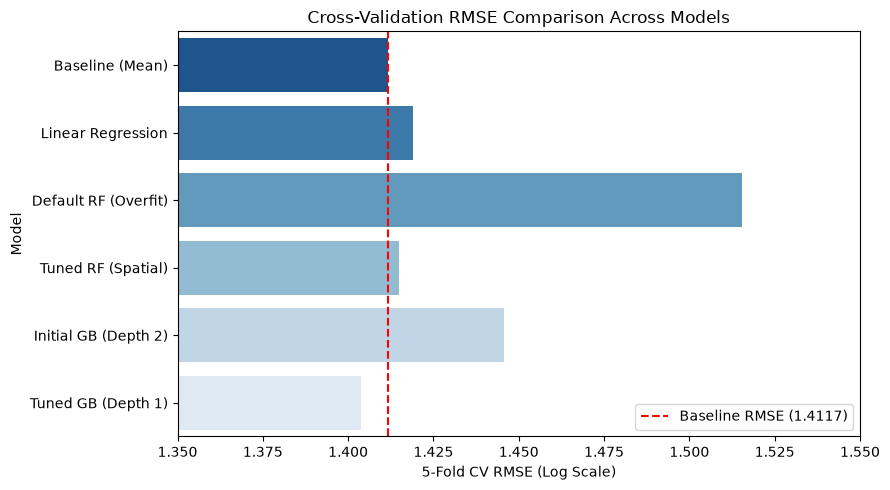

In [12]:
# Prepare models for comparison plot
cv_plot_df = pd.DataFrame({
    'Model': [
        'Baseline (Mean)',
        'Linear Regression',
        'Default RF (Overfit)',
        'Tuned RF (Spatial)',
        'Initial GB (Depth 2)',
        'Tuned GB (Depth 1)'
    ],
    'CV RMSE': [
        baseline_rmse,
        lr_rmse,
        rf_def_val_rmse,
        rf_s_rmse,
        gb_d2_rmse,
        gb_d1_rmse
    ]
})

plt.figure(figsize=(9, 5))
sns.barplot(
    x='CV RMSE',
    y='Model',
    data=cv_plot_df,
    hue='Model',
    palette='Blues_r',
    legend=False
)

# Add vertical dashed line for Baseline RMSE
plt.axvline(
    x=baseline_rmse,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label=f'Baseline RMSE ({baseline_rmse:.4f})'
)

plt.title('Cross-Validation RMSE Comparison Across Models')
plt.xlabel('5-Fold CV RMSE (Log Scale)')
plt.ylabel('Model')
plt.xlim(1.35, 1.55)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('figures/model_cv_rmse_comparison.png', bbox_inches='tight')
plt.show()

### 12. Final Model Evaluation on Unseen Test Set

In [13]:
# Fit the winning model on entire training set
best_model = gb_d1_pipe
best_model.fit(X_train_ns, y_train)

# Predict on unseen test set
y_pred_log = best_model.predict(X_test_ns)
y_pred_log_clipped = np.clip(y_pred_log, 0, None)
y_pred_area = np.expm1(y_pred_log_clipped)

# Metrics on log scale
test_mae_log = mean_absolute_error(y_test, y_pred_log_clipped)
test_rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log_clipped))
test_r2_log = r2_score(y_test, y_pred_log_clipped)

# Metrics on hectare scale
test_mae_ha = mean_absolute_error(y_test_area, y_pred_area)
test_rmse_ha = np.sqrt(mean_squared_error(y_test_area, y_pred_area))
test_r2_ha = r2_score(y_test_area, y_pred_area)

print("--- Final Test Set Evaluation (Log Scale) ---")
print(f"MAE:  {test_mae_log:.4f}")
print(f"RMSE: {test_rmse_log:.4f}")
print(f"R2:   {test_r2_log:.4f}")

print("\n--- Final Test Set Evaluation (Original Hectares Scale) ---")
print(f"MAE:  {test_mae_ha:.4f} ha")
print(f"RMSE: {test_rmse_ha:.4f} ha")
print(f"R2:   {test_r2_ha:.4f}")

--- Final Test Set Evaluation (Log Scale) ---
MAE:  1.0567
RMSE: 1.3298
R2:   -0.0080

--- Final Test Set Evaluation (Original Hectares Scale) ---
MAE:  17.5713 ha
RMSE: 110.9854 ha
R2:   -0.0184


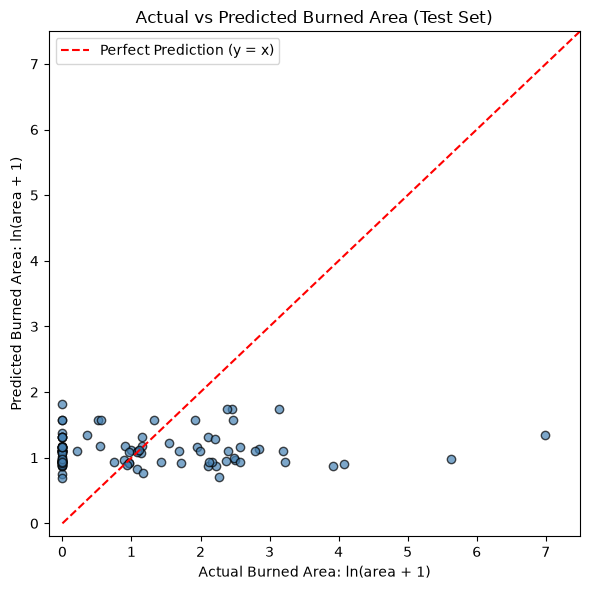

In [14]:
# Scatter plot of actual vs predicted burned area on test set
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_log_clipped, alpha=0.7, color='steelblue', edgecolor='k')

# Red dashed reference line for y = x
max_val = max(y_test.max(), y_pred_log_clipped.max()) + 0.5
plt.plot([0, max_val], [0, max_val], 'r--', linewidth=1.5, label='Perfect Prediction (y = x)')

plt.title('Actual vs Predicted Burned Area (Test Set)')
plt.xlabel('Actual Burned Area: ln(area + 1)')
plt.ylabel('Predicted Burned Area: ln(area + 1)')
plt.xlim(-0.2, max_val)
plt.ylim(-0.2, max_val)
plt.legend()
plt.tight_layout()
plt.savefig('figures/test_actual_vs_predicted.png', bbox_inches='tight')
plt.show()

### 13. Save Trained Model

In [15]:
# Save the best model
model_path = 'models/best_forest_fire_model.joblib'
joblib.dump(best_model, model_path)

print(f"Model saved to: {model_path}")
print(f"File exists: {os.path.exists(model_path)}")
print(f"File size: {os.path.getsize(model_path)} bytes")

Model saved to: models/best_forest_fire_model.joblib
File exists: True
File size: 60020 bytes
